# M00-4 | 改圖：後面會用到的 torch.fx 圖操作

前面三本只「讀」圖。PT2E 的 prepare 和 convert 本質上都是「改圖」：

- `prepare_pt2e` 在圖上插入 observer（M02-2 會親手做一次）。
- `convert_pt2e` 把 observer 換成 quantize／dequantize，並預先算好 int8 weight（M02-3 會親手做一次）。

這本 notebook 用一個 conv → relu 的小圖，把這兩章會用到的改圖動作拆成六步：

| 步驟 | 動作 | 用到的 API | 之後在哪裡用 |
|---|---|---|---|
| 1 | 插入新 node | `add_submodule`、`inserting_after`、`call_module` | M02-2 |
| 2 | 改接下游 | `replace_all_uses_with(delete_user_cb=...)` | M02-2 |
| 3 | 重新產生 forward | `recompile` | M02-2、M02-3 |
| 4 | 用 call_function 取代 | `inserting_before`、`call_function`、`erase_node` | M02-3 |
| 5 | 把常數放進圖裡 | `register_buffer`、`get_attr` | M02-3 |
| 6 | 清理與檢查 | `eliminate_dead_code`、`lint` | M02-3 |

不熟 Graph／Node 的概念（op 種類、args、users…），建議先讀〈[PyTorch FX 的 Graph／Node 一些基礎概念](https://bobondemon.github.io/2025/07/29/%E7%AD%86%E8%A8%98-PyTorch-FX-%E7%9A%84-Graph-Node-%E4%B8%80%E4%BA%9B%E5%9F%BA%E7%A4%8E%E6%A6%82%E5%BF%B5/)〉，
再搭配官方的 [torch.fx 文件](https://docs.pytorch.org/docs/stable/fx.html)。

> **請依序執行。** 六個步驟都在**原地修改同一個 `gm`**，跳著執行或重複執行某一格，圖就會和說明對不上。要重來請 Restart 後從頭執行全部。

In [1]:
import copy

import torch

from common.models import example_inputs, get_model
from common.pt2e import export_module, quiet
from common.viz import draw

quiet()
_ = torch.manual_seed(0)


def first_line(e):
    """例外訊息只取第一行（後面多半是建議與 stack 資訊）。"""
    return str(e).splitlines()[0]


class Scale(torch.nn.Module):
    """示範用的小模組：把輸入乘上 k。只是為了有個看得出效果的 call_module 目標。"""

    def __init__(self, k):
        super().__init__()
        self.k = k

    def forward(self, x):
        return x * self.k

## 起點：conv → relu

`export_module()` 底下是 `torch.export.export(...).module()`。`base` 存下原始輸出，之後每一步都拿來驗證。

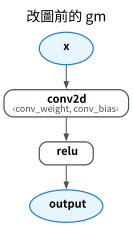

In [2]:
x = example_inputs(4)[0]
gm = export_module(get_model("conv_relu").eval(), (x,))
with torch.no_grad():
    base = gm(x).clone()
graph = gm.graph
nodes = {n.name: n for n in graph.nodes}  # 用名字找 node：x、conv2d、relu、output…
relu = nodes["relu"]
draw(gm, title="改圖前的 gm")

In [3]:
print(f"relu.args  = {relu.args}   ← 它吃誰（上游）")
print(f"relu.users = {list(relu.users)}   ← 誰吃它（下游）")

relu.args  = (conv2d,)   ← 它吃誰（上游）
relu.users = [output]   ← 誰吃它（下游）


改圖時幾乎都在處理這兩件事：「新 node 插在誰後面」與「讓誰改吃新的 node」。

## Step 1：插入新 node

`call_module` 的目標必須先掛在 GraphModule 上（`add_submodule`）。在 `inserting_after(relu)` 這個 context 裡建立的 node，會放在 relu 之後。

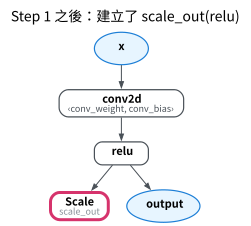

In [4]:
gm.add_submodule("scale_out", Scale(2.0))
with graph.inserting_after(relu):
    scale = graph.call_module("scale_out", (relu,))  # scale_out(relu)
draw(gm, highlight=["scale_out"], title="Step 1 之後：建立了 scale_out(relu)")

In [5]:
print(f"scale.users = {list(scale.users)}")
assert not scale.users

scale.users = []


`scale_out` 吃 relu，但**沒有人吃它**：output 仍然吃 relu。建立 node 不會自動把它接進圖裡，接下游是下一步。

## Step 2：改接下游

目標是讓原本吃 relu 的人（output）改吃 `scale_out`。直覺的寫法是 `relu.replace_all_uses_with(scale)`。
先在副本 `gm_bad` 上試試看：

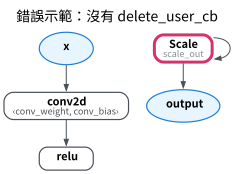

In [6]:
gm_bad = copy.deepcopy(gm)
relu_bad = next(n for n in gm_bad.graph.nodes if n.name == "relu")
scale_bad = next(n for n in gm_bad.graph.nodes if n.name == "scale_out")
relu_bad.replace_all_uses_with(scale_bad)
draw(gm_bad, highlight=["scale_out"], title="錯誤示範：沒有 delete_user_cb")

In [7]:
print(f"gm_bad 的 scale_out.args = {scale_bad.args}")
try:
    gm_bad.graph.lint()
    lint_error = None
except RuntimeError as e:
    lint_error = first_line(e)
print(f"gm_bad.graph.lint()：{lint_error}")
assert scale_bad.args == (scale_bad,) and lint_error is not None

gm_bad 的 scale_out.args = (scale_out,)
gm_bad.graph.lint()：Argument 'scale_out' of Node 'scale_out' was used before it has been defined! Please check that Nodes in the graph are topologically ordered


`scale_out` 被改成**吃自己**（圖上的自我迴圈），relu 反而沒人吃了。
因為 Step 1 建立時 `scale_out.args = (relu,)`，`scale_out` 自己也是 relu 的使用者；`replace_all_uses_with` 把「所有」使用者都改掉，連它自己也一起改了。

正確做法是用 `delete_user_cb` 排除新 node 自己：

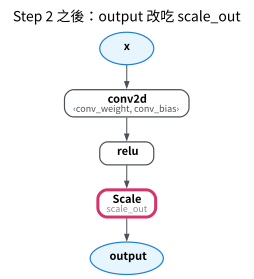

In [8]:
relu.replace_all_uses_with(scale, delete_user_cb=lambda user: user is not scale)
draw(gm, highlight=["scale_out"], title="Step 2 之後：output 改吃 scale_out")

In [9]:
print(f"relu.users = {list(relu.users)}   scale.args = {scale.args}")
assert list(relu.users) == [scale] and scale.args == (relu,)

relu.users = [scale_out]   scale.args = (relu,)


「在 A 後面插新 node B」的標準寫法：B 吃 A，其餘原本吃 A 的人改吃 B（B 自己除外）。
這正是 `prepare_pt2e` 插 observer 的動作。

## Step 3：recompile

圖改好了，但呼叫 `gm(x)` 的結果呢？

In [10]:
with torch.no_grad():
    before_recompile = torch.equal(gm(x), base)
gm.recompile()
with torch.no_grad():
    after_recompile = torch.allclose(gm(x), base * 2)
print(f"改完圖、還沒 recompile：輸出仍等於原輸出？ {before_recompile}")
print(f"recompile 之後：輸出 == 2 × 原輸出？       {after_recompile}")
assert before_recompile and after_recompile

改完圖、還沒 recompile：輸出仍等於原輸出？ True
recompile 之後：輸出 == 2 × 原輸出？       True


GraphModule 的 forward 是**由圖產生的程式碼**。改圖不會自動重新產生，每次改完都要 `recompile()`。

## Step 4：用 call_function 取代 call_module

把 `scale_out` 這個 call_module 換成一個 `aten.mul` 的 call_function。`convert_pt2e` 把 observer（call_module）換成 q/dq（call_function）就是同一個模式。
順序是：建新 node → 下游改吃新的 → 刪舊的。先看看順序錯了會怎樣：

In [11]:
with graph.inserting_before(scale):
    mul = graph.call_function(torch.ops.aten.mul.Tensor, (relu, 2.0))
try:
    graph.erase_node(scale)  # 還有人吃 scale，不能刪
    erase_error = None
except RuntimeError as e:
    erase_error = first_line(e)
print(f"直接 erase_node(scale)：{erase_error}")
assert erase_error is not None

直接 erase_node(scale)：Tried to erase Node scale_out but it still had 1 users in the graph: {output: None}!


還有人吃 `scale_out` 時不能刪。照正確順序做：

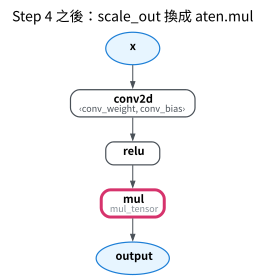

In [12]:
scale.replace_all_uses_with(mul)  # 先讓下游改吃新 node
graph.erase_node(scale)           # 沒有人吃了，才能刪
gm.delete_submodule("scale_out")  # 模組也一併丟掉
gm.recompile()
with torch.no_grad():
    assert torch.allclose(gm(x), base * 2)
draw(gm, highlight=[mul.name], title="Step 4 之後：scale_out 換成 aten.mul")

輸出仍是 2 倍。`mul` 的第二個參數 `2.0` 是直接寫在 node 參數裡的 Python 常數（圖上看不到，它不是 node）。

## Step 5：把 tensor 常數放進圖裡

Python 數字可以直接寫在參數裡，對應 per-tensor 的 scale／zero point（M01 看過 q/dq 上的 scale 就是這樣）。
tensor 常數（對應 per-channel 的 scale／zero point）要先註冊成 buffer，再用 `get_attr` node 讀出來：

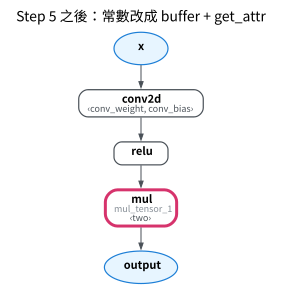

In [13]:
gm.register_buffer("two", torch.tensor(2.0))
with graph.inserting_before(mul):
    two = graph.get_attr("two")  # 讀 GraphModule 上名叫 two 的屬性
    mul_t = graph.call_function(torch.ops.aten.mul.Tensor, (relu, two))
mul.replace_all_uses_with(mul_t)
graph.erase_node(mul)
gm.recompile()
with torch.no_grad():
    assert torch.allclose(gm(x), base * 2)
draw(gm, highlight=[mul_t.name], title="Step 5 之後：常數改成 buffer + get_attr")

`two` 是 get_attr，畫在使用它的 `mul` 標籤的 `‹…›` 裡。

## Step 6：清理與檢查

故意建一個沒人用的 `neg`，再用 `eliminate_dead_code` 清掉。`lint` 檢查圖的結構是否一致（例如 node 是否先定義再使用），有問題會丟例外。

In [14]:
with graph.inserting_after(relu):
    graph.call_function(torch.ops.aten.neg.default, (relu,))  # 沒有人吃它
n_before = len(graph.nodes)
graph.eliminate_dead_code()  # 刪掉所有「沒有使用者、也沒有副作用」的 node
n_after = len(graph.nodes)
graph.lint()
gm.recompile()
print(f"node 數：插入 neg 後 {n_before} → eliminate_dead_code 後 {n_after}")
assert n_after == n_before - 1 and not any(n.name.startswith("neg") for n in graph.nodes)

node 數：插入 neg 後 10 → eliminate_dead_code 後 9


convert 把 weight 的 quantize 預先算好、換成 get_attr 之後，原本的 weight node 就沒人吃了，也是靠 `eliminate_dead_code` 清掉（M02-3）。

## 小結

| 要做的事 | 動作 |
|---|---|
| 插 observer | `add_submodule` + `inserting_after` + `call_module` + `replace_all_uses_with(delete_user_cb=...)` |
| observer → q/dq | `inserting_before` + `call_function` + `replace_all_uses_with` + `erase_node`（+ `delete_submodule`） |
| 存 scale／zero point | Python 常數寫在參數裡，或 `register_buffer` + `get_attr` |
| 收尾 | `eliminate_dead_code`、`lint`、`recompile` |

M02-2 的插 observer 就是 Step 1～3；M02-3 把 observer 換成 q/dq、預先量化 weight，就是 Step 4～6。